In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("Dataset\processed_train.csv")

np.random.seed(42)

engine_ids = df["Engine_ID"].unique()
np.random.shuffle(engine_ids)

train_ids = engine_ids[:70]
val_ids = engine_ids[70:85]
test_ids = engine_ids[85:]

train_df = df[df["Engine_ID"].isin(train_ids)].copy()
val_df = df[df["Engine_ID"].isin(val_ids)].copy()
test_df = df[df["Engine_ID"].isin(test_ids)].copy()

print("Training engines:", train_df["Engine_ID"].nunique())
print("Validation engines:", val_df["Engine_ID"].nunique())
print("Testing engines:", test_df["Engine_ID"].nunique())

Training engines: 70
Validation engines: 15
Testing engines: 15


In [3]:
FEATURES = [
    "Setting_1",
    "Setting_2",
    "Sensor_2",
    "Sensor_3",
    "Sensor_4",
    "Sensor_6",
    "Sensor_7",
    "Sensor_8",
    "Sensor_9",
    "Sensor_11",
    "Sensor_12",
    "Sensor_13",
    "Sensor_14",
    "Sensor_15",
    "Sensor_17",
    "Sensor_20",
    "Sensor_21"
]

TARGET = "RUL"



In [4]:
WINDOW = 30

def create_sequences(data, features, target, window=30):
    X = []
    y = []
    
    for engine_id, engine_data in data.groupby("Engine_ID"):
        
        engine_data = engine_data.sort_values("Cycle")
        
        feature_values = engine_data[features].values.astype("float32")
        target_values = engine_data[target].values.astype("float32")
        
        for i in range(window, len(engine_data)):
            
            X.append(
                feature_values[i-window:i]
            )
            
            y.append(
                target_values[i]
            )
    
    return np.array(X), np.array(y)

In [5]:
X_train, y_train = create_sequences(
    train_df,
    FEATURES,
    TARGET,
    WINDOW
)

X_val, y_val = create_sequences(
    val_df,
    FEATURES,
    TARGET,
    WINDOW
)

X_test, y_test = create_sequences(
    test_df,
    FEATURES,
    TARGET,
    WINDOW
)

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(12216, 30, 17)
(2720, 30, 17)
(2695, 30, 17)


BiLSTM

In [6]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    LSTM,
    Bidirectional,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.random.set_seed(42)

bilstm = Sequential([
    
    Input(shape=(WINDOW, len(FEATURES))),
    
    Bidirectional(
        LSTM(
            64,
            return_sequences=True
        )
    ),
    
    Dropout(0.2),
    
    Bidirectional(
        LSTM(32)
    ),
    
    Dropout(0.2),
    
    Dense(
        32,
        activation="relu"
    ),
    
    Dense(1)
])

bilstm.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse",
    metrics=["mae"]
)

bilstm.summary()

C:\Users\Shivam\AppData\Roaming\Python\Python310\site-packages\google\api_core\_python_version_support.py:273: FutureWarning: You are using a Python version (3.10.2) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 30, 128)        │        41,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 85,313 (333.25 KB)

 Trainable params: 85,313 (333.25 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6
)

history_bilstm = bilstm.fit(
    X_train,
    y_train,
    
    validation_data=(
        X_val,
        y_val
    ),
    
    epochs=100,
    batch_size=64,
    
    shuffle=False,
    
    callbacks=[
        early_stopping,
        reduce_lr
    ],
    
    verbose=1
)

Epoch 1/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - loss: 3862.0808 - mae: 52.3079 - val_loss: 1777.4382 - val_mae: 37.8245 - learning_rate: 0.0010
Epoch 2/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - loss: 1775.0332 - mae: 37.3792 - val_loss: 1748.7185 - val_mae: 37.1358 - learning_rate: 0.0010
Epoch 3/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 8s 39ms/step - loss: 1774.6118 - mae: 37.3078 - val_loss: 1748.7272 - val_mae: 37.1241 - learning_rate: 0.0010
Epoch 4/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - loss: 1769.9578 - mae: 37.2435 - val_loss: 1748.8000 - val_mae: 37.1100 - learning_rate: 0.0010
Epoch 5/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - loss: 1787.8455 - mae: 37.4305 - val_loss: 1747.1984 - val_mae: 37.1188 - learning_rate: 0.0010
Epoch 6/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - loss: 1724.8242 - mae: 36.1941 - val_loss: 1697.0767 - val_mae: 36.6504 - learning_rate: 0.0010
Epoch 7/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - loss: 1395.0092 - mae: 32.7171 

LSTM

In [8]:
lstm = Sequential([
    
    Input(shape=(WINDOW, len(FEATURES))),
    
    LSTM(
        64,
        return_sequences=True
    ),
    
    Dropout(0.2),
    
    LSTM(32),
    
    Dropout(0.2),
    
    Dense(
        32,
        activation="relu"
    ),
    
    Dense(1)
])

lstm.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="mse",
    metrics=["mae"]
)

history_lstm = lstm.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=64,
    shuffle=False,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        )
    ]
)

Epoch 1/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - loss: 5355.7246 - mae: 62.4639 - val_loss: 2828.5120 - val_mae: 46.2236
Epoch 2/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 2025.6661 - mae: 39.7457 - val_loss: 1760.1647 - val_mae: 37.5438
Epoch 3/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 1807.9404 - mae: 37.7091 - val_loss: 1751.4772 - val_mae: 37.3350
Epoch 4/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 1808.9360 - mae: 37.5761 - val_loss: 1749.1885 - val_mae: 37.2365
Epoch 5/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 1803.1549 - mae: 37.4890 - val_loss: 1749.1639 - val_mae: 37.2348
Epoch 6/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 1798.4032 - mae: 37.4276 - val_loss: 1749.1777 - val_mae: 37.2365
Epoch 7/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 1789.3610 - mae: 37.3559 - val_loss: 1748.8856 - val_mae: 37.2188
Epoch 8/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 1807.6621 - mae: 37.5041 - val_loss: 1747

GRU

In [9]:
from tensorflow.keras.layers import GRU

gru = Sequential([
    
    Input(shape=(WINDOW, len(FEATURES))),
    
    GRU(
        64,
        return_sequences=True
    ),
    
    Dropout(0.2),
    
    GRU(32),
    
    Dropout(0.2),
    
    Dense(
        32,
        activation="relu"
    ),
    
    Dense(1)
])

gru.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="mse",
    metrics=["mae"]
)

history_gru = gru.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=64,
    shuffle=False,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        )
    ]
)

Epoch 1/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - loss: 5438.7466 - mae: 63.0062 - val_loss: 2926.5369 - val_mae: 46.9022
Epoch 2/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 2054.3269 - mae: 39.9997 - val_loss: 1761.9779 - val_mae: 37.5775
Epoch 3/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 1797.7178 - mae: 37.5424 - val_loss: 1749.4305 - val_mae: 37.2509
Epoch 4/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 1795.8922 - mae: 37.4167 - val_loss: 1749.3223 - val_mae: 37.2447
Epoch 5/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 1796.9301 - mae: 37.4445 - val_loss: 1744.9891 - val_mae: 37.2059
Epoch 6/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 1702.3651 - mae: 36.2111 - val_loss: 1749.9756 - val_mae: 37.0223
Epoch 7/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 1478.4969 - mae: 33.5378 - val_loss: 983.4465 - val_mae: 28.0373
Epoch 8/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 807.7598 - mae: 23.6532 - val_loss: 487.29

TCN

In [10]:
import numpy as np
import tensorflow as tf

from tensorflow.keras.layers import (
    Input,
    Conv1D,
    Dropout,
    Add,
    Activation,
    Lambda,
    Dense
)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

tf.keras.backend.clear_session()
tf.random.set_seed(42)
np.random.seed(42)


def tcn_block(x, filters, kernel_size, dilation_rate, dropout=0.1):
    residual = x

    # First dilated causal convolution
    x = Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        padding="causal",
        dilation_rate=dilation_rate,
        activation="relu"
    )(x)

    x = Dropout(dropout)(x)

    # Second dilated causal convolution
    x = Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        padding="causal",
        dilation_rate=dilation_rate,
        activation="relu"
    )(x)

    x = Dropout(dropout)(x)

    # Match dimensions for residual connection
    if residual.shape[-1] != filters:
        residual = Conv1D(
            filters=filters,
            kernel_size=1,
            padding="same"
        )(residual)

    x = Add()([x, residual])
    x = Activation("relu")(x)

    return x

In [11]:
inputs = Input(
    shape=(X_train.shape[1], X_train.shape[2])
)

x = tcn_block(
    inputs,
    filters=32,
    kernel_size=2,
    dilation_rate=1
)

x = tcn_block(
    x,
    filters=32,
    kernel_size=2,
    dilation_rate=2
)

x = tcn_block(
    x,
    filters=32,
    kernel_size=2,
    dilation_rate=4
)

x = tcn_block(
    x,
    filters=32,
    kernel_size=2,
    dilation_rate=8
)

# Take representation from the latest cycle
x = Lambda(lambda z: z[:, -1, :])(x)

x = Dense(
    32,
    activation="relu"
)(x)

x = Dropout(0.1)(x)

outputs = Dense(1)(x)

tcn = Model(
    inputs=inputs,
    outputs=outputs
)

tcn.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse",
    metrics=["mae"]
)

tcn.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 30, 17)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 30, 32)    │      1,120 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 30, 32)    │          0 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 30, 32)    │      2,080 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 30, 32)    │          0 │ conv1d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 30, 32)    │        576 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 30, 32)    │          0 │ dropout_1[0][0],  │
│                     │                   │            │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 30, 32)    │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 30, 32)    │      2,080 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 30, 32)    │          0 │ conv1d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 30, 32)    │      2,080 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 30, 32)    │          0 │ conv1d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 30, 32)    │          0 │ dropout_3[0][0],  │
│                     │                   │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 30, 32)    │          0 │ add_1[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 30, 32)    │      2,080 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 30, 32)    │          0 │ conv1d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 30, 32)    │      2,080 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 30, 32)    │          0 │ conv1d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 30, 32)    │          0 │ dropout_5[0][0],  │
│                     │                   │            │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 30, 32)    │          0 │ add_2[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 30, 32)    │      2,080 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 17,345 (67.75 KB)

 Trainable params: 17,345 (67.75 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

history_tcn = tcn.fit(
    X_train,
    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=100,
    batch_size=64,

    shuffle=True,

    callbacks=[
        early_stop,
        reduce_lr
    ],

    verbose=1
)

Epoch 1/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 1686.8795 - mae: 31.0799 - val_loss: 527.4921 - val_mae: 18.3741 - learning_rate: 0.0010
Epoch 2/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 606.9047 - mae: 19.3551 - val_loss: 450.1514 - val_mae: 17.8070 - learning_rate: 0.0010
Epoch 3/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 535.4882 - mae: 17.9855 - val_loss: 444.1293 - val_mae: 17.7244 - learning_rate: 0.0010
Epoch 4/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 510.0025 - mae: 17.3948 - val_loss: 436.2255 - val_mae: 17.5025 - learning_rate: 0.0010
Epoch 5/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 479.4751 - mae: 16.8791 - val_loss: 452.6161 - val_mae: 17.9029 - learning_rate: 0.0010
Epoch 6/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 455.2206 - mae: 16.3384 - val_loss: 420.7164 - val_mae: 16.9871 - learning_rate: 0.0010
Epoch 7/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 449.8182 - mae: 16.2795 - val_loss: 4

In [13]:
tcn_pred = tcn.predict(
    X_test,
    verbose=0
).ravel()

print(tcn_pred[:10])
print(y_test[:10])

[115.98128  113.11188  112.216805 113.72271  114.193085 113.15896
 114.30574  113.60879  109.88418  107.973076]
[125. 125. 125. 125. 125. 125. 125. 125. 125. 125.]


In [14]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

tcn_mae = mean_absolute_error(
    y_test,
    tcn_pred
)

tcn_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        tcn_pred
    )
)

tcn_r2 = r2_score(
    y_test,
    tcn_pred
)

print("TCN MAE :", tcn_mae)
print("TCN RMSE:", tcn_rmse)
print("TCN R²  :", tcn_r2)

TCN MAE : 13.062564849853516
TCN RMSE: 16.758336056798065
TCN R²  : 0.8392554521560669


Random Forest

In [15]:
X_train_flat = X_train.reshape(
    X_train.shape[0],
    -1
)

X_val_flat = X_val.reshape(
    X_val.shape[0],
    -1
)

X_test_flat = X_test.reshape(
    X_test.shape[0],
    -1
)

print(X_train_flat.shape)

(12216, 510)


In [16]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf.fit(
    X_train_flat,
    y_train
)

rf_pred = rf.predict(
    X_test_flat
)

XGBoost

In [17]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=700,
    learning_rate=0.03,
    max_depth=6,
    min_child_weight=3,
    
    subsample=0.8,
    colsample_bytree=0.8,
    
    objective="reg:squarederror",
    
    random_state=42,
    n_jobs=-1
)

xgb.fit(
    X_train_flat,
    y_train,
    
    eval_set=[
        (
            X_val_flat,
            y_val
        )
    ],
    
    verbose=False
)

xgb_pred = xgb.predict(
    X_test_flat
)

Evaluation

In [18]:
bilstm_pred = bilstm.predict(
    X_test,
    verbose=0
).ravel()

lstm_pred = lstm.predict(
    X_test,
    verbose=0
).ravel()

gru_pred = gru.predict(
    X_test,
    verbose=0
).ravel()

tcn_pred = tcn.predict(
    X_test,
    verbose=0
).ravel()

In [19]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


def nasa_score(actual, predicted):
    """NASA / PHM08 asymmetric RUL scoring function (Saxena et al., 2008).
    Penalizes late predictions (predicted RUL > actual RUL) more heavily
    than early ones, since a late prediction means maintenance would be
    scheduled after the engine could already have failed.
    """
    d = np.asarray(predicted) - np.asarray(actual)
    s = np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)
    return np.sum(s)


def evaluate_model(name, actual, predicted):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    r2 = r2_score(
        actual,
        predicted
    )

    score = nasa_score(
        actual,
        predicted
    )

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Score": score
    }


In [20]:
results = [
    
    evaluate_model(
        "BiLSTM",
        y_test,
        bilstm_pred
    ),
    
    evaluate_model(
        "LSTM",
        y_test,
        lstm_pred
    ),
    
    evaluate_model(
        "GRU",
        y_test,
        gru_pred
    ),
    
    evaluate_model(
        "TCN",
        y_test,
        tcn_pred
    ),
    
    evaluate_model(
        "Random Forest",
        y_test,
        rf_pred
    ),
    
    evaluate_model(
        "XGBoost",
        y_test,
        xgb_pred
    )
]

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE"
)

print(results_df)

           Model        MAE       RMSE        R2         Score
2            GRU   9.850574  13.600701  0.894124   9685.893555
0         BiLSTM   9.853040  14.054794  0.886936  10247.986328
1           LSTM  10.931690  14.859698  0.873615  12135.567383
3            TCN  13.062565  16.758336  0.839255  11804.945312
5        XGBoost  13.019043  16.843858  0.837611  15340.459961
4  Random Forest  16.186462  20.567649  0.757873  34967.439111


Testing

In [21]:
test_data = pd.read_csv("Dataset\processed_test.csv")
test_data

,Engine_ID,Cycle,Setting_1,Setting_2,Setting_3,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_5,...,Sensor_12,Sensor_13,Sensor_14,Sensor_15,Sensor_16,Sensor_17,Sensor_18,Sensor_19,Sensor_20,Sensor_21
0,1,1,0.632184,0.750000,0.0,0.0,0.545181,0.310661,0.269413,0.0,...,0.646055,0.220588,0.132160,0.308965,0.0,0.333333,0.0,0.0,0.558140,0.661834
1,1,2,0.344828,0.250000,0.0,0.0,0.150602,0.379551,0.222316,0.0,...,0.739872,0.264706,0.204768,0.213159,0.0,0.416667,0.0,0.0,0.682171,0.686827
2,1,3,0.517241,0.583333,0.0,0.0,0.376506,0.346632,0.322248,0.0,...,0.699360,0.220588,0.155640,0.458638,0.0,0.416667,0.0,0.0,0.728682,0.721348
3,1,4,0.741379,0.500000,0.0,0.0,0.370482,0.285154,0.408001,0.0,...,0.573561,0.250000,0.170090,0.257022,0.0,0.250000,0.0,0.0,0.666667,0.662110
4,1,5,0.580460,0.500000,0.0,0.0,0.391566,0.352082,0.332039,0.0,...,0.737740,0.220588,0.152751,0.300885,0.0,0.166667,0.0,0.0,0.658915,0.716377
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13091,100,194,0.781609,0.500000,0.0,0.0,0.611446,0.619359,0.566172,0.0,...,0.426439,0.176471,0.584890,0.564063,0.0,0.500000,0.0,0.0,0.395349,0.418669
13092,100,195,0.436782,0.416667,0.0,0.0,0.605422,0.537388,0.671843,0.0,...,0.503198,0.308824,0.572350,0.485956,0.0,0.583333,0.0,0.0,0.333333,0.528721
13093,100,196,0.465517,0.250000,0.0,0.0,0.671687,0.482014,0.414754,0.0,...,0.530917,0.235294,0.605326,0.507888,0.0,0.583333,0.0,0.0,0.372093,0.429301
13094,100,197,0.281609,0.583333,0.0,0.0,0.617470,0.522128,0.626435,0.0,...,0.562900,0.294118,0.622046,0.562524,0.0,0.583333,0.0,0.0,0.403101,0.518779


In [22]:
def create_test_sequences(test_df, features, window=30):
    X = []
    engine_ids = []

    for engine_id, engine_data in test_df.groupby("Engine_ID"):
        engine_data = engine_data.sort_values("Cycle")

        values = engine_data[features].values.astype("float32")

        if len(values) >= window:
            X.append(values[-window:])
            engine_ids.append(engine_id)

    return np.array(X), np.array(engine_ids)

In [23]:
X_final_test, test_engine_ids = create_test_sequences(
    test_data,
    FEATURES,
    WINDOW
)

print(X_final_test.shape)

(100, 30, 17)


In [24]:
predicted_rul = lstm.predict(
    X_final_test,
    verbose=0
).ravel()

In [25]:
rul_df = pd.read_csv(r"Dataset\RUL_FD001.csv")

print(rul_df.head())
print(rul_df.shape)

   RUL
0  112
1   98
2   69
3   82
4   91
(100, 1)


In [26]:
RUL_CAP = 125

rul_df["Engine_ID"] = np.arange(
    1,
    len(rul_df) + 1
)

rul_df["RUL"] = rul_df["RUL"].clip(upper=RUL_CAP)

pred_df = pd.DataFrame({
    "Engine_ID": test_engine_ids,
    "Predicted_RUL": predicted_rul
})

comparison = pred_df.merge(
    rul_df,
    on="Engine_ID"
)


In [27]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

actual = comparison["RUL"]
predicted = comparison["Predicted_RUL"]

mae = mean_absolute_error(actual, predicted)

rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

r2 = r2_score(actual, predicted)

print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 10.02883529663086
RMSE: 13.748869138510651
R²  : 0.8822870254516602


In [28]:
bilstm_pred = bilstm.predict(X_final_test, verbose=0).ravel()
lstm_pred   = lstm.predict(X_final_test, verbose=0).ravel()
gru_pred    = gru.predict(X_final_test, verbose=0).ravel()
tcn_pred    = tcn.predict(X_final_test, verbose=0).ravel()

In [29]:
X_final_test_flat = X_final_test.reshape(
    X_final_test.shape[0],
    -1
)

rf_pred = rf.predict(X_final_test_flat)
xgb_pred = xgb.predict(X_final_test_flat)

In [30]:
def evaluate_official(name, y_true, y_pred):
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "Score": nasa_score(y_true, y_pred)
    }

official_results = [
    evaluate_official("BiLSTM", actual, bilstm_pred),
    evaluate_official("LSTM", actual, lstm_pred),
    evaluate_official("GRU", actual, gru_pred),
    evaluate_official("TCN", actual, tcn_pred),
    evaluate_official("Random Forest", actual, rf_pred),
    evaluate_official("XGBoost", actual, xgb_pred)
]

official_results_df = pd.DataFrame(
    official_results
).sort_values("RMSE")

print(official_results_df)


           Model        MAE       RMSE        R2       Score
2            GRU  10.391902  13.739993  0.882439  321.776996
1           LSTM  10.028835  13.748869  0.882287  350.479253
0         BiLSTM  10.429395  13.797675  0.881450  324.404597
5        XGBoost  10.521955  13.821884  0.881033  313.752590
3            TCN  10.655154  14.482809  0.869384  316.972461
4  Random Forest  13.037140  17.629998  0.806449  795.112964


Plotting

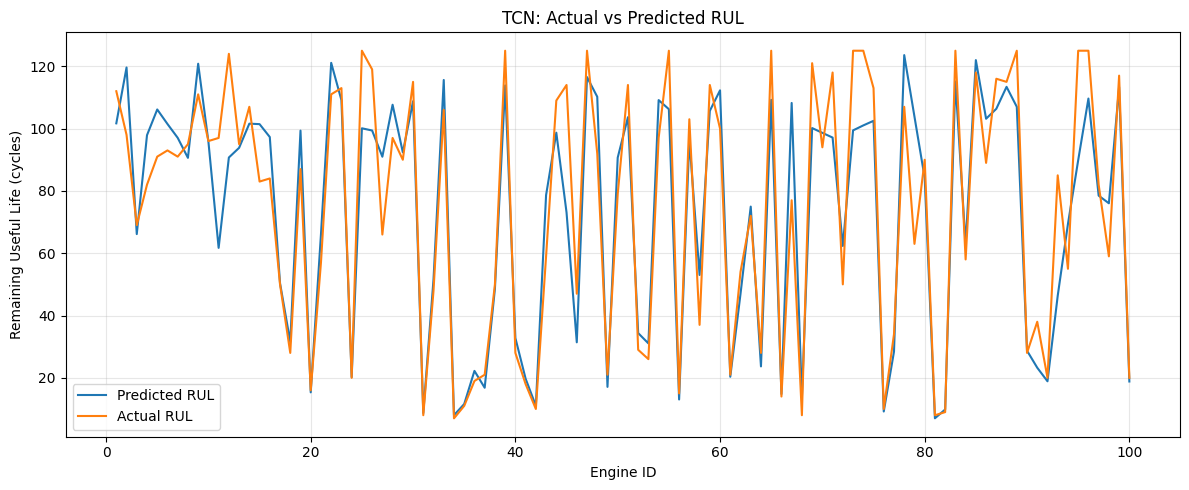

In [31]:
import matplotlib.pyplot as plt
import numpy as np

# Make sure both are 1-D
actual_plot = np.asarray(actual).ravel()
tcn_plot = np.asarray(tcn_pred).ravel()

engine_ids = np.arange(1, len(actual_plot) + 1)

plt.figure(figsize=(12, 5))

plt.plot(
    engine_ids,
    tcn_plot,
    label="Predicted RUL"
)

plt.plot(
    engine_ids,
    actual_plot,
    label="Actual RUL"
)

plt.xlabel("Engine ID")
plt.ylabel("Remaining Useful Life (cycles)")
plt.title("TCN: Actual vs Predicted RUL")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

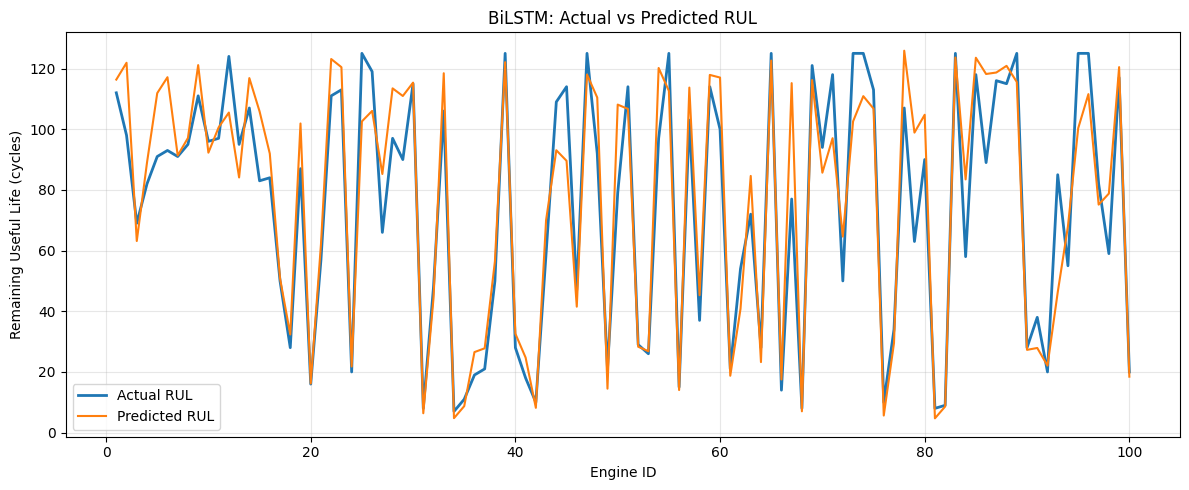

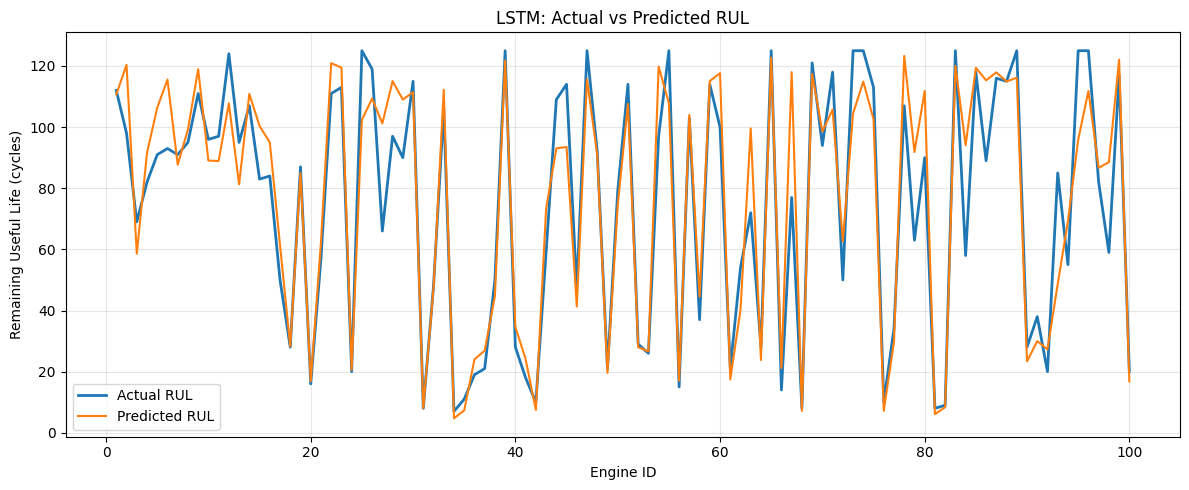

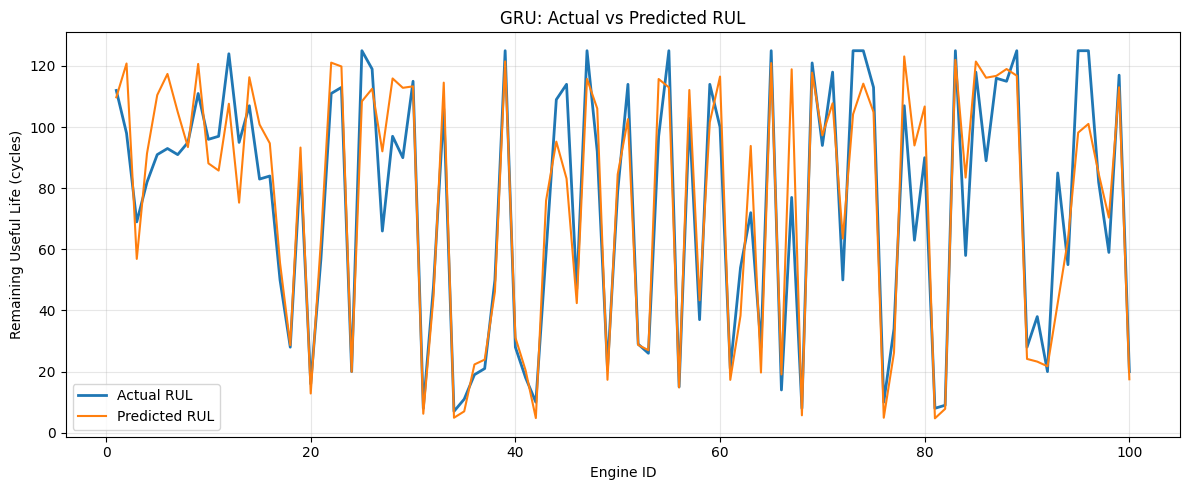

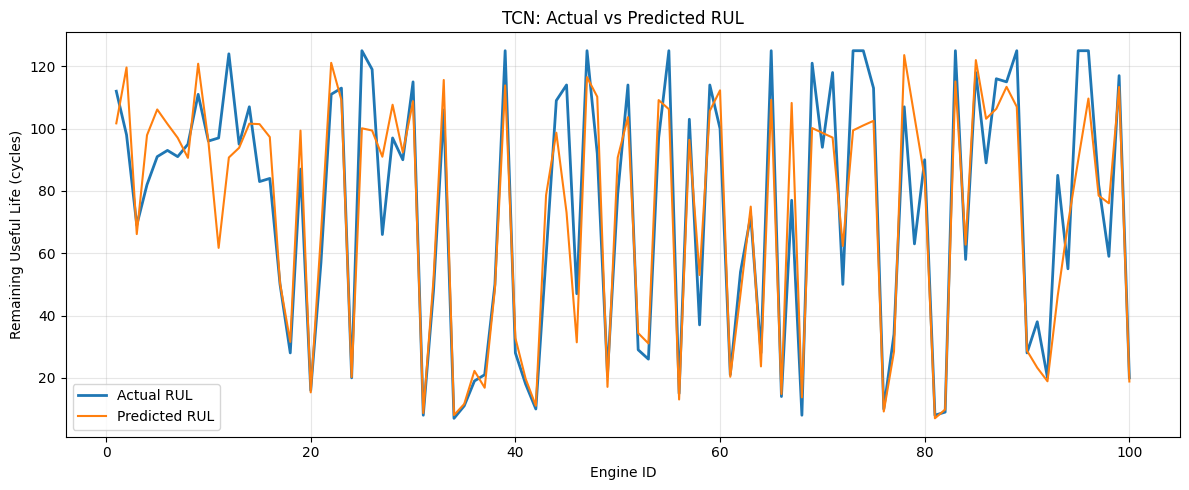

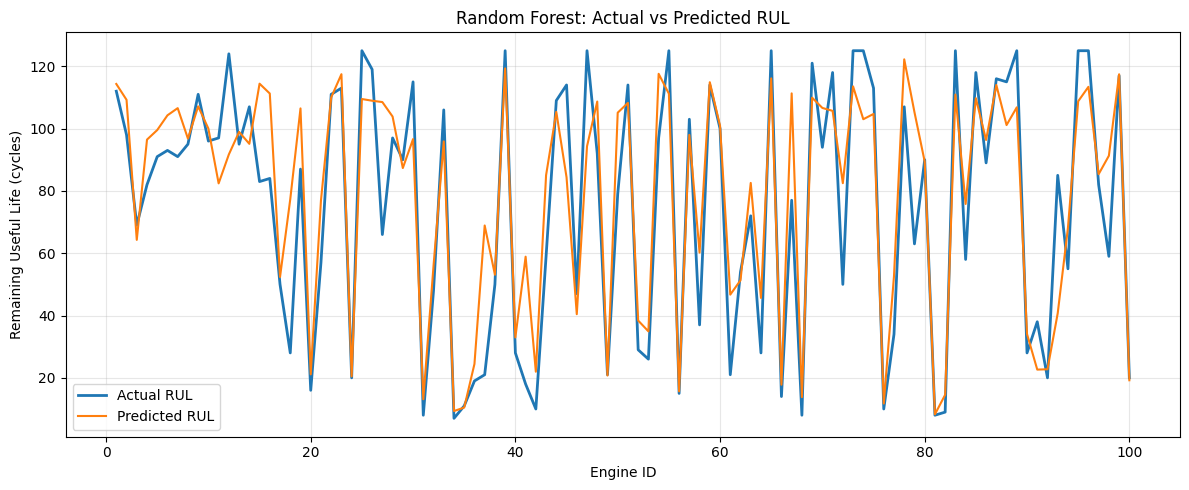

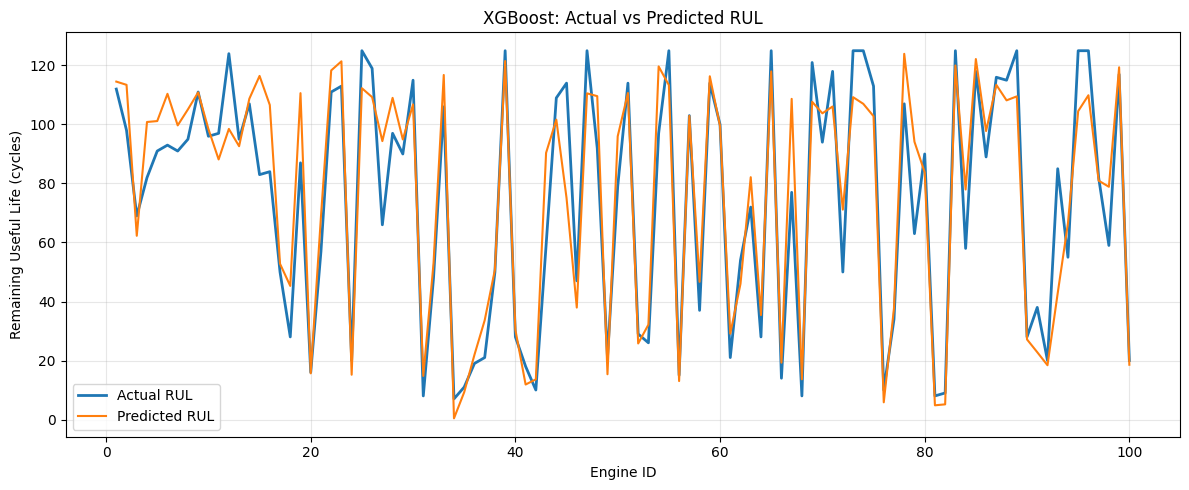

In [32]:
predictions = {
    "BiLSTM": bilstm_pred,
    "LSTM": lstm_pred,
    "GRU": gru_pred,
    "TCN": tcn_pred,
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred
}

actual_plot = np.asarray(actual).ravel()
engine_ids = np.arange(1, len(actual_plot) + 1)

for model_name, pred in predictions.items():

    pred = np.asarray(pred).ravel()

    plt.figure(figsize=(12, 5))

    plt.plot(
        engine_ids,
        actual_plot,
        label="Actual RUL",
        linewidth=2
    )

    plt.plot(
        engine_ids,
        pred,
        label="Predicted RUL",
        linewidth=1.5
    )

    plt.xlabel("Engine ID")
    plt.ylabel("Remaining Useful Life (cycles)")
    plt.title(f"{model_name}: Actual vs Predicted RUL")

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

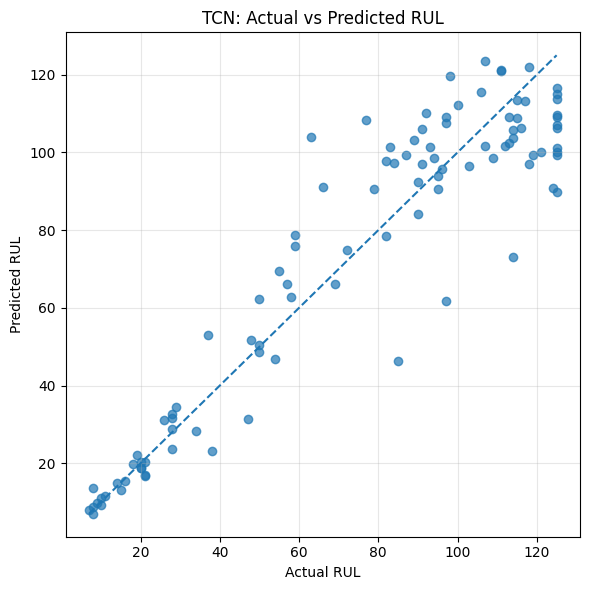

In [33]:
plt.figure(figsize=(6, 6))

plt.scatter(
    actual_plot,
    tcn_pred,
    alpha=0.7
)

minimum = min(
    actual_plot.min(),
    np.min(tcn_pred)
)

maximum = max(
    actual_plot.max(),
    np.max(tcn_pred)
)

# Perfect-prediction reference
plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")

plt.title(
    "TCN: Actual vs Predicted RUL"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()